# Étude de cas : ventes et livraisons

Une entreprise vend des produits en ligne (épicerie, frais, boissons, hygiène, maison, électronique, livres, bricolage, collection) et les livre elle-même, depuis ses entrepôts de la région parisienne, avec sa propre flotte de véhicules.

### Les fichiers (`/work/data`)

| Fichier | Contenu |
|---|---|
| `produits.csv` | le catalogue : `produit_id, nom, categorie, sous_categorie, prix, poids_kg` |
| `commandes.csv` | le journal des commandes, une ligne par événement : `commande_id, client_id, horodatage, evenement, livreur_id, detail` |
| `vehicules/<vehicule>/<AAAA-MM>.csv` | la trace GPS de chaque véhicule, **un point par minute** : `timestamp, livreur_id, lon, lat, vitesse_kmh, dans_vehicule, charge_kg` |
| `communes.csv` | les communes de Paris et de la petite couronne et les 20 arrondissements de Paris, avec leur centre : `commune, code_postal, lon, lat` |
| `communes.geojson` | les contours des mêmes communes (propriétés `commune`, `code_postal`) |

### Le journal des commandes

Une commande apparaît plusieurs fois : une ligne par étape.

| `evenement` | Sens | `livreur_id` | `detail` |
|---|---|---|---|
| `commande` | le client passe commande | — | les produits : `P0201x1\|P0033x4` (produit `x` quantité) |
| `chargee` | la commande est chargée dans un véhicule | le livreur | — |
| `livree` | le client signe ; horodatage à la seconde | le livreur | — |
| `echec` | la livraison n'a pas pu se faire | le livreur | le motif |
| `reportee` | chargée mais pas tentée : rapportée à l'entrepôt en fin de service | le livreur | — |
| `retour` | la commande est abandonnée et retournée à l'entrepôt | le livreur | — |

### Les traces GPS

Un livreur conduit un seul véhicule par jour. `dans_vehicule` vaut `false` quand le livreur est descendu du véhicule ; `charge_kg` est le poids transporté.

### Les services

| Adresse | Service |
|---|---|
| http://localhost:8888 | JupyterLab |
| http://localhost:8080 | Master Spark |
| http://localhost:4040 | Spark UI de la session ouverte |
| http://localhost:18080 | Spark History |
| `mongodb://mongo:27017` | MongoDB |

## 1) Charger la donnée

1.1) La session Spark et les fonctions fournies.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T
from pyspark.sql.window import Window

spark = (SparkSession.builder
         .appName("livraisons")
         .master("spark://spark-master:7077")
         .getOrCreate())
DATA = "/work/data"
RESULTATS = "/work/resultats"


def haversine(lon1, lat1, lon2, lat2):
    """Distance en km entre deux points : noms de colonnes ou colonnes, en degrés."""
    lon1, lat1, lon2, lat2 = [F.col(c) if isinstance(c, str) else c for c in (lon1, lat1, lon2, lat2)]
    dlon = F.radians(lon2 - lon1)
    dlat = F.radians(lat2 - lat1)
    a = F.sin(dlat / 2) ** 2 + F.cos(F.radians(lat1)) * F.cos(F.radians(lat2)) * F.sin(dlon / 2) ** 2
    return 2 * 6371.0 * F.asin(F.sqrt(a))

11:42:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


1.2) Définissez un schéma explicite (`StructType`) pour chacun des 4 fichiers CSV, puis chargez `produits.csv`, `commandes.csv`, `communes.csv` et **tous** les fichiers GPS en une seule lecture (`vehicules/*/*.csv`). Les horodatages doivent être de type `timestamp`, `dans_vehicule` de type `boolean`, les nombres de type `double`.

Affichez le nombre de lignes de chaque DataFrame.



In [2]:
schema_produits = T.StructType([
    T.StructField("produit_id", T.StringType()),
    T.StructField("nom", T.StringType()),
    T.StructField("categorie", T.StringType()),
    T.StructField("sous_categorie", T.StringType()),
    T.StructField("prix", T.DoubleType()),
    T.StructField("poids_kg", T.DoubleType()),
])
schema_journal = T.StructType([
    T.StructField("commande_id", T.StringType()),
    T.StructField("client_id", T.StringType()),
    T.StructField("horodatage", T.TimestampType()),
    T.StructField("evenement", T.StringType()),
    T.StructField("livreur_id", T.StringType()),
    T.StructField("detail", T.StringType()),
])
schema_communes = T.StructType([
    T.StructField("commune", T.StringType()),
    T.StructField("code_postal", T.StringType()),
    T.StructField("lon", T.DoubleType()),
    T.StructField("lat", T.DoubleType()),
])
schema_gps = T.StructType([
    T.StructField("timestamp", T.TimestampType()),
    T.StructField("livreur_id", T.StringType()),
    T.StructField("lon", T.DoubleType()),
    T.StructField("lat", T.DoubleType()),
    T.StructField("vitesse_kmh", T.DoubleType()),
    T.StructField("dans_vehicule", T.BooleanType()),
    T.StructField("charge_kg", T.DoubleType()),
])

produits = spark.read.csv(f"{DATA}/produits.csv", header=True, schema=schema_produits)
journal  = spark.read.csv(f"{DATA}/commandes.csv", header=True, schema=schema_journal)
communes = spark.read.csv(f"{DATA}/communes.csv", header=True, schema=schema_communes)
gps      = spark.read.csv(f"{DATA}/vehicules/*/*.csv", header=True, schema=schema_gps)

print("produits :", produits.count())
print("journal  :", journal.count())
print("communes :", communes.count())
print("gps      :", gps.count())


produits : 233


journal  : 846535
communes : 142


gps      : 5174905


1.3) L'identifiant du véhicule n'est pas une colonne des fichiers GPS : il est dans le chemin du fichier. Ajoutez une colonne `vehicule_id` (fonction `F.input_file_name()`), et une colonne `jour` (la date du point).

In [3]:
gps = (gps
       .withColumn("vehicule_id", F.regexp_extract(F.input_file_name(), r"vehicules/([^/]+)/", 1))
       .withColumn("jour", F.to_date("timestamp")))
gps.show(5)


+-------------------+----------+--------+---------+-----------+-------------+---------+-----------+----------+
|          timestamp|livreur_id|     lon|      lat|vitesse_kmh|dans_vehicule|charge_kg|vehicule_id|      jour|
+-------------------+----------+--------+---------+-----------+-------------+---------+-----------+----------+
|2025-10-01 07:40:00|      L001|2.277083|48.936735|        0.0|        false|   2581.6|        V18|2025-10-01|
|2025-10-01 07:41:00|      L001|2.277083|48.936735|        0.0|        false|   2581.6|        V18|2025-10-01|
|2025-10-01 07:42:00|      L001|2.277084|48.936734|        0.0|        false|   2581.6|        V18|2025-10-01|
|2025-10-01 07:43:00|      L001|2.277083|48.936734|        0.0|        false|   2581.6|        V18|2025-10-01|
|2025-10-01 07:44:00|      L001|2.277084|48.936733|        0.0|        false|   2581.6|        V18|2025-10-01|
+-------------------+----------+--------+---------+-----------+-------------+---------+-----------+----------+
o

## 2) Vérifier la donnée

2.1) Combien y a-t-il de commandes, de clients, de livreurs et de véhicules ?

In [4]:
journal.agg(F.countDistinct("commande_id").alias("nb_commandes"),
            F.countDistinct("client_id").alias("nb_clients"),
            F.countDistinct("livreur_id").alias("nb_livreurs")).show()
gps.agg(F.countDistinct("vehicule_id").alias("nb_vehicules")).show()


+------------+----------+-----------+
|nb_commandes|nb_clients|nb_livreurs|
+------------+----------+-----------+
|      271617|      8000|         90|
+------------+----------+-----------+



+------------+
|nb_vehicules|
+------------+
|          72|
+------------+



2.2) Comptez les événements du journal par type.

In [6]:
journal.groupBy("evenement").count().orderBy(F.desc("count")).show()

+---------+------+
|evenement| count|
+---------+------+
|  chargee|286862|
| commande|271617|
|   livree|268682|
|    echec| 11220|
| reportee|  6960|
|   retour|  1194|
+---------+------+



2.3) Pour chaque commande, comptez ses événements `chargee`. Combien de commandes ont été chargées 0, 1, 2, 3… fois ?

In [12]:
nb_charge = journal.groupBy("commande_id").agg(
    F.sum(F.when(F.col("evenement") == "chargee", 1).otherwise(0)).alias("nb_chargee"))

nb_charge.groupBy("nb_chargee").count().orderBy("nb_chargee").show()
print("Total commandes  :", nb_charge.count())                                   # 271617 (= 2.1)
print("Total chargements :", nb_charge.agg(F.sum("nb_chargee")).first()[0])      # 286862 (= 2.2)



+----------+------+
|nb_chargee| count|
+----------+------+
|         0|  1637|
|         1|254229|
|         2| 14673|
|         3|  1026|
|         4|    51|
|         5|     1|
+----------+------+



Total commandes  : 271617


Total chargements : 286862


ici j'ai  voulu garder les commandes jmais chargées. si j'avais fait un filter par evnement chargé, les non chargées auraient disparu

2.4) Pour chaque événement `chargee`, trouvez l'événement qui le précède dans la vie de la même commande. Comptez les `chargee` par événement précédent.

In [13]:
w_cmd = Window.partitionBy("commande_id").orderBy("horodatage")

journal_prec = journal.withColumn("evenement_precedent", F.lag("evenement").over(w_cmd))

(journal_prec.filter(F.col("evenement") == "chargee")
    .groupBy("evenement_precedent").count()
    .orderBy(F.desc("count")).show())
print("Total :", journal_prec.filter(F.col("evenement") == "chargee").count())   # 286862 (= 2.2)

## la partition range ensemble les evenement d'une meme commande, et order by va trié dans l'orde chronologique.. le f.lag va chercher la valeur de la ligne juste avant.

+-------------------+------+
|evenement_precedent| count|
+-------------------+------+
|           commande|269980|
|              echec|  9950|
|           reportee|  6932|
+-------------------+------+



Total : 286862


*Un rechargement suit toujours un `echec` (nouvelle tentative) ou un `reportee` (commande rapportée en fin de service) : il y a plus de `chargee` que de `commande`.*

2.5) Au 31/12/2025, combien de commandes ne sont pas livrées ? Séparez les commandes abandonnées (événement `retour`) des commandes encore en cours.

In [9]:
statut = journal.groupBy("commande_id").agg(
    F.max(F.when(F.col("evenement") == "livree", 1).otherwise(0)).alias("est_livree"),
    F.max(F.when(F.col("evenement") == "retour", 1).otherwise(0)).alias("est_retour"))

non_livrees = statut.filter("est_livree = 0")

print("Commandes non livrées au 31/12 :", non_livrees.count())
print("  - abandonnées (retour)        :", non_livrees.filter("est_retour = 1").count())
print("  - encore en cours             :", non_livrees.filter("est_retour = 0").count())
## ici on cherhce si c'est arrivé au moins une fois avec max (est_retour = 1 correspond aux commandes abandonnées)

Commandes non livrées au 31/12 : 2935


  - abandonnées (retour)        : 1194


  - encore en cours             : 1741


## 3) Les lignes de commande

3.1) Les produits d'une commande sont dans la colonne `detail` de l'événement `commande`. Construisez la table `lignes` : une ligne par produit commandé, avec `commande_id`, `client_id`, `horodatage`, `produit_id`, `quantite`.

In [16]:
lignes_brutes = (journal.filter(F.col("evenement") == "commande")
    .withColumn("produit", F.explode(F.split("detail", r"\|")))
    .withColumn("produit_id", F.split("produit", "x")[0])
    .withColumn("quantite", F.split("produit", "x")[1].cast("int"))
    .select("commande_id", "client_id", "horodatage", "produit_id", "quantite"))

lignes_brutes.filter(F.col("commande_id") == "C0000001").show(truncate=False)
print("Lignes de commande :", lignes_brutes.count())


+-----------+---------+-------------------+----------+--------+
|commande_id|client_id|horodatage         |produit_id|quantite|
+-----------+---------+-------------------+----------+--------+
|C0000001   |CL05658  |2025-01-01 00:03:44|P0037     |5       |
|C0000001   |CL05658  |2025-01-01 00:03:44|P0063     |1       |
|C0000001   |CL05658  |2025-01-01 00:03:44|P0019     |2       |
|C0000001   |CL05658  |2025-01-01 00:03:44|P0067     |1       |
|C0000001   |CL05658  |2025-01-01 00:03:44|P0069     |2       |
|C0000001   |CL05658  |2025-01-01 00:03:44|P0089     |3       |
|C0000001   |CL05658  |2025-01-01 00:03:44|P0061     |1       |
|C0000001   |CL05658  |2025-01-01 00:03:44|P0055     |2       |
|C0000001   |CL05658  |2025-01-01 00:03:44|P0009     |3       |
|C0000001   |CL05658  |2025-01-01 00:03:44|P0076     |1       |
|C0000001   |CL05658  |2025-01-01 00:03:44|P0107     |1       |
|C0000001   |CL05658  |2025-01-01 00:03:44|P0005     |2       |
|C0000001   |CL05658  |2025-01-01 00:03:

Lignes de commande : 4779049


3.2) Ajoutez à `lignes` les colonnes du catalogue et le `montant` de chaque ligne. Construisez la table `commandes` : une ligne par commande, avec `montant`, `poids_kg` et `nb_lignes`.

In [17]:
lignes = (lignes_brutes.join(produits, "produit_id", "left")
          .withColumn("montant", F.round(F.col("prix") * F.col("quantite"), 2))
          .cache())

commandes = (lignes.groupBy("commande_id", "client_id", "horodatage").agg(
                 F.round(F.sum("montant"), 2).alias("montant"),
                 F.round(F.sum(F.col("poids_kg") * F.col("quantite")), 2).alias("poids_kg"),
                 F.count("*").alias("nb_lignes"))
             .cache())

lignes.filter(F.col("commande_id") == "C0000001") \
      .select("commande_id", "produit_id", "nom", "categorie", "quantite", "prix", "montant").show(truncate=False)
commandes.orderBy("commande_id").show(5)

print("Lignes de commande :", lignes.count())
print("Commandes          :", commandes.count(), "(attendu 271617, cf. 2.1)")
print("Produits sans prix :", lignes.filter(F.col("prix").isNull()).count(), "(attendu 0)")


+-----------+----------+----------------------------+-----------------+--------+----+-------+
|commande_id|produit_id|nom                         |categorie        |quantite|prix|montant|
+-----------+----------+----------------------------+-----------------+--------+----+-------+
|C0000001   |P0037     |Cookies chocolat 300 g      |Épicerie         |5       |2.6 |13.0   |
|C0000001   |P0063     |Lardons fumés 200 g         |Frais            |1       |2.4 |2.4    |
|C0000001   |P0019     |Capsules café x30           |Épicerie         |2       |8.5 |17.0   |
|C0000001   |P0067     |Bananes 1 kg                |Frais            |1       |1.9 |1.9    |
|C0000001   |P0069     |Tomates grappe 1 kg         |Frais            |2       |3.4 |6.8    |
|C0000001   |P0089     |Sirop de grenadine 75 cl    |Boissons         |3       |2.6 |7.8    |
|C0000001   |P0061     |Jambon blanc x4             |Frais            |1       |3.2 |3.2    |
|C0000001   |P0055     |Emmental râpé 200 g         |Frais  

+-----------+---------+-------------------+-------+--------+---------+
|commande_id|client_id|         horodatage|montant|poids_kg|nb_lignes|
+-----------+---------+-------------------+-------+--------+---------+
|   C0000001|  CL05658|2025-01-01 00:03:44| 103.65|   21.61|       19|
|   C0000002|  CL02895|2025-01-01 00:06:58|   91.3|    18.7|       15|
|   C0000003|  CL03531|2025-01-01 00:18:34|   46.0|    15.9|        9|
|   C0000004|  CL00699|2025-01-01 00:29:59|   62.1|    5.99|        8|
|   C0000005|  CL07863|2025-01-01 00:30:28|   85.4|   23.55|       13|
+-----------+---------+-------------------+-------+--------+---------+
only showing top 5 rows

Lignes de commande : 4779049


Commandes          : 271617 (attendu 271617, cf. 2.1)
Produits sans prix : 0 (attendu 0)


## 4) Les entrepôts

4.1) Pour chaque véhicule et chaque jour, gardez le premier et le dernier point GPS. Arrondissez leurs coordonnées à 0,01° et comptez les journées par position arrondie. Combien d'entrepôts y a-t-il ?

In [18]:
jours = gps.groupBy("vehicule_id", "jour").agg(
    F.min_by("lon", "timestamp").alias("lon_debut"),
    F.min_by("lat", "timestamp").alias("lat_debut"),
    F.max_by("lon", "timestamp").alias("lon_fin"),
    F.max_by("lat", "timestamp").alias("lat_fin")).cache()

debuts = jours.select(F.round("lon_debut", 2).alias("lon"), F.round("lat_debut", 2).alias("lat"))
fins   = jours.select(F.round("lon_fin", 2).alias("lon"), F.round("lat_fin", 2).alias("lat"))

positions = (debuts.union(fins)
             .groupBy("lon", "lat").agg(F.count("*").alias("nb_journees"))
             .orderBy(F.desc("nb_journees")))
positions.show()

nb_jours = jours.count()
print("Journées véhicule            :", nb_jours)
print("Points début + fin           :", nb_jours * 2)
print("Points sur ces positions     :", positions.agg(F.sum("nb_journees")).first()[0])
print("Nombre d'entrepôts           :", positions.count())


+----+-----+-----------+
| lon|  lat|nb_journees|
+----+-----+-----------+
|2.45|48.91|       8434|
|2.28|48.94|       6416|
|2.35|48.75|       5934|
+----+-----+-----------+



Journées véhicule            : 10392
Points début + fin           : 20784


Points sur ces positions     : 20784


Nombre d'entrepôts           : 3


Chaque jour, les véhicules partent et reviennent toujours à l'une des 3 mêmes positions : il y a donc 3 entrepôts.

4.2) Construisez la table `entrepots` (`entrepot`, `lon`, `lat`) : `E1`, `E2`… par longitude croissante, position = moyenne des premiers points. Construisez la table `vehicule_entrepot` (`vehicule_id`, `entrepot`) et comptez les véhicules par entrepôt.

In [20]:
# 1) Les entrepôts : position moyenne des premiers points, numérotés de l'ouest vers l'est
entrepots = (jours
    .withColumn("lon_r", F.round("lon_debut", 2))
    .withColumn("lat_r", F.round("lat_debut", 2))
    .groupBy("lon_r", "lat_r")
    .agg(F.round(F.avg("lon_debut"), 5).alias("lon"),
         F.round(F.avg("lat_debut"), 5).alias("lat")))
entrepots = entrepots.withColumn("entrepot",
                F.concat(F.lit("E"), F.row_number().over(Window.orderBy("lon")))).cache()

# 2) Le véhicule -> son entrepôt (celui de ses départs du matin)
vehicule_entrepot = (jours
    .withColumn("lon_r", F.round("lon_debut", 2))
    .withColumn("lat_r", F.round("lat_debut", 2))
    .join(entrepots, ["lon_r", "lat_r"])
    .select("vehicule_id", "entrepot").distinct().cache())

(jours.join(vehicule_entrepot, "vehicule_id")
    .groupBy("entrepot")
    .agg(F.countDistinct("vehicule_id").alias("nb_vehicules"),
         F.count("*").alias("nb_journees"))
    .withColumn("journees_par_vehicule", F.round(F.col("nb_journees") / F.col("nb_vehicules"), 0))
    .orderBy("entrepot").show())


entrepots.select("entrepot", "lon", "lat").orderBy("entrepot").show()
vehicule_entrepot.groupBy("entrepot").agg(F.count("*").alias("nb_vehicules")).orderBy("entrepot").show()

print("Véhicules rattachés         :", vehicule_entrepot.count(), "(attendu 72, cf. 2.1)")
print("Véhicules différents        :", vehicule_entrepot.select("vehicule_id").distinct().count())


14:05:25 WARN CacheManager: Asked to cache already cached data.
14:05:25 WARN CacheManager: Asked to cache already cached data.


+--------+------------+-----------+---------------------+
|entrepot|nb_vehicules|nb_journees|journees_par_vehicule|
+--------+------------+-----------+---------------------+
|      E1|          24|       3208|                134.0|
|      E2|          24|       2967|                124.0|
|      E3|          24|       4217|                176.0|
+--------+------------+-----------+---------------------+

+--------+-------+--------+
|entrepot|    lon|     lat|
+--------+-------+--------+
|      E1|2.27707|48.93671|
|      E2|2.35151|48.74705|
|      E3|2.44896| 48.9067|
+--------+-------+--------+



+--------+------------+
|entrepot|nb_vehicules|
+--------+------------+
|      E1|          24|
|      E2|          24|
|      E3|          24|
+--------+------------+



Véhicules rattachés         : 72 (attendu 72, cf. 2.1)


Véhicules différents        : 72


On nomme les 3 entrepôts E1, E2, E3 et on rattache chaque véhicule à l'entrepôt d'où il part le matin : il y a 24 véhicules par entrepôt. En comptant les jours où chaque véhicule a roulé, on voit que E3 est le plus actif (environ 176 jours par véhicule, contre environ 125 à 135 pour E1 et E2).

## 5) Les livraisons

On découpe la journée de chaque livreur en **livraisons** : une livraison commence quand le livreur descend du véhicule et dure jusqu'à la livraison suivante. Le chargement du matin, les retours à l'entrepôt et la pause déjeuner sont aussi des périodes à pied : la question 5.6 les distingue.

5.1) Ajoutez à `gps` une colonne `changement` : 1 si le livreur vient de descendre du véhicule (point précédent du même livreur, le même jour, `dans_vehicule = true` ; point courant `false`), 0 sinon. Le premier point de la journée vaut 0.

Affichez les lignes où `changement = 1` pour le livreur `L001` le 2025-01-06.

In [21]:
w_liv = Window.partitionBy("livreur_id", "jour").orderBy("timestamp")

gps = gps.withColumn("avant", F.lag("dans_vehicule").over(w_liv))
gps = gps.withColumn("changement",
        F.when((F.col("avant") == True) & (F.col("dans_vehicule") == False), 1).otherwise(0))

l001 = gps.filter((F.col("livreur_id") == "L001") & (F.col("jour") == "2025-01-06"))

l001.filter(F.col("changement") == 1) \
    .select("timestamp", "vehicule_id", "lon", "lat", "charge_kg", "changement") \
    .orderBy("timestamp").show(50)

print("Descentes du véhicule ce jour-là :", l001.agg(F.sum("changement")).first()[0])
print("Premier point de la journée      :", l001.orderBy("timestamp").select("timestamp", "changement").first())
## prtition va regarder chaque livreur par jour, orderby = trié dans l'ordre des minutes. f.lag vas regarder la minute d'avant (est ce qu'il etait dans la voiture avant) si avant etant dans
##le vehicule et apres non, changement =1

+-------------------+-----------+--------+---------+---------+----------+
|          timestamp|vehicule_id|     lon|      lat|charge_kg|changement|
+-------------------+-----------+--------+---------+---------+----------+
|2025-01-06 09:54:00|        V10|2.311953|48.871389|   1143.9|         1|
|2025-01-06 10:00:00|        V10|2.313447|48.870848|   1089.1|         1|
|2025-01-06 10:09:00|        V10|2.316012|48.872919|   1085.5|         1|
|2025-01-06 10:23:00|        V10|2.325412|48.874465|    959.0|         1|
|2025-01-06 10:36:00|        V10| 2.32844|48.866695|    916.7|         1|
|2025-01-06 10:54:00|        V10|2.337183|48.866435|    915.7|         1|
|2025-01-06 11:12:00|        V10|2.317523|48.857452|    874.0|         1|
|2025-01-06 11:38:00|        V10|2.317717|48.850169|    840.6|         1|
|2025-01-06 12:02:00|        V10|2.312056|48.845401|    530.9|         1|
|2025-01-06 12:15:00|        V10|2.305215|48.854413|    496.5|         1|
|2025-01-06 13:04:00|        V10|2.298

Descentes du véhicule ce jour-là : 16


Premier point de la journée      : Row(timestamp=datetime.datetime(2025, 1, 6, 6, 43), changement=0)


Le 6 janvier, L001 descend 16 fois, et la charge du véhicule baisse au fil des arrêts : ce sont bien ses livraisons.

5.2) Ajoutez une colonne `numero_livraison` : la somme cumulée de `changement` pour chaque livreur et chaque jour. Elle vaut 0 au chargement du matin.

Pour `L001` le 2025-01-06, affichez par `numero_livraison` le premier et le dernier timestamp, et le nombre de minutes à pied.

In [22]:
gps = gps.withColumn("numero_livraison", F.sum("changement").over(w_liv)).cache()

(gps.filter((F.col("livreur_id") == "L001") & (F.col("jour") == "2025-01-06"))
    .groupBy("numero_livraison")
    .agg(F.min("timestamp").alias("premier"),
         F.max("timestamp").alias("dernier"),
         F.sum(F.when(F.col("dans_vehicule") == False, 1).otherwise(0)).alias("minutes_a_pied"))
    .orderBy("numero_livraison")
    .show(100))

+----------------+-------------------+-------------------+--------------+
|numero_livraison|            premier|            dernier|minutes_a_pied|
+----------------+-------------------+-------------------+--------------+
|               0|2025-01-06 07:43:00|2025-01-06 09:53:00|            44|
|               1|2025-01-06 09:54:00|2025-01-06 09:59:00|             4|
|               2|2025-01-06 10:00:00|2025-01-06 10:08:00|             7|
|               3|2025-01-06 10:09:00|2025-01-06 10:22:00|            10|
|               4|2025-01-06 10:23:00|2025-01-06 10:35:00|             4|
|               5|2025-01-06 10:36:00|2025-01-06 10:53:00|             8|
|               6|2025-01-06 10:54:00|2025-01-06 11:11:00|             4|
|               7|2025-01-06 11:12:00|2025-01-06 11:37:00|            18|
|               8|2025-01-06 11:38:00|2025-01-06 12:01:00|            17|
|               9|2025-01-06 12:02:00|2025-01-06 12:14:00|             4|
|              10|2025-01-06 12:15:00|

La somme cumulée de changement numérote les livraisons : 0 pour le chargement du matin, puis +1 à chaque descente du véhicule. Le 6 janvier, L001 a des livraisons numérotées de 0 à 17, ce qui correspond aux 16 descentes trouvées en 5.1. La plupart durent quelques minutes à pied ; les plus longues sont sans doute la pause déjeuner et le retour à l'entrepôt.

5.3) Construisez la table `livraisons` : une ligne par (`livreur_id`, `jour`, `numero_livraison`), calculée sur les seuls points où le livreur est à pied, avec `vehicule_id`, `debut`, `fin`, `duree_min` (nombre de points) et la position moyenne `lon`, `lat`. Combien de lignes contient-elle ?

In [23]:
cle = ["livreur_id", "jour", "numero_livraison"]

livraisons = (gps.filter(F.col("dans_vehicule") == False)
    .groupBy(cle)
    .agg(F.first("vehicule_id").alias("vehicule_id"),
         F.min("timestamp").alias("debut"),
         F.max("timestamp").alias("fin"),
         F.count("*").alias("duree_min"),
         F.round(F.avg("lon"), 6).alias("lon"),
         F.round(F.avg("lat"), 6).alias("lat"))
    .cache())

print("Nombre de lignes dans livraisons :", livraisons.count())

# Vérification : on retrouve les durées de la 5.2 pour L001
livraisons.filter((F.col("livreur_id") == "L001") & (F.col("jour") == "2025-01-06")) \
          .orderBy("numero_livraison").show(20)

# Vérification : toutes les minutes à pied sont bien dans la table
print("Minutes à pied dans gps        :", gps.filter(F.col("dans_vehicule") == False).count())
print("Somme des duree_min            :", livraisons.agg(F.sum("duree_min")).first()[0])
 ##  faire une ligne par livraison, avec seulement le moment où le livreur est à pied.

Nombre de lignes dans livraisons : 273593


+----------+----------+----------------+-----------+-------------------+-------------------+---------+--------+---------+
|livreur_id|      jour|numero_livraison|vehicule_id|              debut|                fin|duree_min|     lon|      lat|
+----------+----------+----------------+-----------+-------------------+-------------------+---------+--------+---------+
|      L001|2025-01-06|               0|        V10|2025-01-06 07:43:00|2025-01-06 08:26:00|       44|2.277131|48.936703|
|      L001|2025-01-06|               1|        V10|2025-01-06 09:54:00|2025-01-06 09:57:00|        4|2.311953| 48.87139|
|      L001|2025-01-06|               2|        V10|2025-01-06 10:00:00|2025-01-06 10:06:00|        7|2.313447|48.870848|
|      L001|2025-01-06|               3|        V10|2025-01-06 10:09:00|2025-01-06 10:18:00|       10|2.316013| 48.87292|
|      L001|2025-01-06|               4|        V10|2025-01-06 10:23:00|2025-01-06 10:26:00|        4|2.325412|48.874465|
|      L001|2025-01-06| 

Minutes à pied dans gps        : 2843285


Somme des duree_min            : 2843285


La table livraisons contient 273593 lignes : une par période à pied (livreur, jour, numéro). Pour L001 le 6 janvier, on retrouve les mêmes durées qu'en 5.2. La somme des durées est égale au nombre total de minutes à pied : aucune minute n'est perdue.

5.4) Ajoutez à chaque livraison ses signatures et ses échecs. Un événement `livree` ou `echec` appartient à une livraison quand il a le même livreur, le même jour, et un horodatage compris entre `debut` et `fin`, avec 1 minute de marge de chaque côté : les points GPS sont à la minute, les événements à la seconde.

Construisez la table `livraisons_ev` : les colonnes de `livraisons`, plus `signature` (horodatage de l'événement), `evenement`, `commande_id` et `client_id`. Une ligne par événement ; une livraison sans événement garde une ligne, avec ces 4 colonnes vides.

In [24]:
ev = journal.filter(F.col("evenement").isin("livree", "echec")).select(
    F.col("livreur_id").alias("liv"),
    F.to_date("horodatage").alias("jour_ev"),
    F.col("horodatage").alias("signature"),
    "evenement", "commande_id", "client_id")

marge = F.expr("INTERVAL 1 MINUTE")
condition = ((livraisons.livreur_id == ev.liv) &
             (livraisons.jour == ev.jour_ev) &
             (ev.signature >= livraisons.debut - marge) &
             (ev.signature <= livraisons.fin + marge))

livraisons_ev = livraisons.join(ev, condition, "left").drop("liv", "jour_ev").cache()

# Exemple : L001 le 6 janvier
(livraisons_ev.filter((F.col("livreur_id") == "L001") & (F.col("jour") == "2025-01-06"))
    .select("numero_livraison", "debut", "fin", "signature", "evenement", "commande_id", "client_id")
    .orderBy("numero_livraison", "signature").show(50))

# Vérifications
print("Lignes dans livraisons_ev       :", livraisons_ev.count())
print("Livraisons (doit être = 5.3)    :", livraisons_ev.select(cle).distinct().count())
print("Événements livree/echec journal :", ev.count())
print("Événements rattachés            :", livraisons_ev.filter(F.col("commande_id").isNotNull()).count())

##bu : avoir quelles commandes ont été remises ou ratées pendant chaque arrêt du livreur.
## on garde que les evenement livré
## on renomme livreur_id en liv et on créer jour_ev 
## condition de jointeure : un ev appartient au meme livereu quand c'ts le meme livreur, le meme jour et l'ev est entre le debut et la fin de la livraison à 1min prés

+----------------+-------------------+-------------------+-------------------+---------+-----------+---------+
|numero_livraison|              debut|                fin|          signature|evenement|commande_id|client_id|
+----------------+-------------------+-------------------+-------------------+---------+-----------+---------+
|               0|2025-01-06 07:43:00|2025-01-06 08:26:00|               NULL|     NULL|       NULL|     NULL|
|               1|2025-01-06 09:54:00|2025-01-06 09:57:00|2025-01-06 09:54:50|   livree|   C0001606|  CL07994|
|               2|2025-01-06 10:00:00|2025-01-06 10:06:00|2025-01-06 10:02:25|   livree|   C0001917|  CL02560|
|               3|2025-01-06 10:09:00|2025-01-06 10:18:00|2025-01-06 10:13:28|   livree|   C0002443|  CL05981|
|               4|2025-01-06 10:23:00|2025-01-06 10:26:00|2025-01-06 10:24:48|   livree|   C0001770|  CL04561|
|               5|2025-01-06 10:36:00|2025-01-06 10:43:00|2025-01-06 10:42:05|   livree|   C0002251|  CL05834|
|

Lignes dans livraisons_ev       : 307237


Livraisons (doit être = 5.3)    : 273593


Événements livree/echec journal : 279902


Événements rattachés            : 279902


le mem nbre de livraison qu'audessu, donc pas de perte avec le left join.307 237 lignes au total − 279 902 lignes avec un événement = 27 335 lignes sans événement

5.5) Combien d'événements `livree` et `echec` du journal ne sont rattachés à aucune livraison ?

In [25]:
rattaches = (livraisons_ev.filter(F.col("commande_id").isNotNull())
             .select("commande_id", "signature", "evenement"))

# 1) Les événements du journal qui ne sont dans aucune livraison
orphelins = ev.join(rattaches, ["commande_id", "signature", "evenement"], "left_anti")
print("Événements non rattachés :", orphelins.count())
orphelins.groupBy("evenement").count().show()

# 2) Vérification : aucun événement rattaché à 2 livraisons à la fois
doublons = rattaches.groupBy("commande_id", "signature", "evenement").count().filter("count > 1")
print("Événements rattachés à plusieurs livraisons :", doublons.count())


Événements non rattachés : 0


+---------+-----+
|evenement|count|
+---------+-----+
+---------+-----+



Événements rattachés à plusieurs livraisons : 0


il n'ya aucun evenement orphelin et aucun duplicata

5.6) Toutes les périodes à pied ne sont pas des livraisons. Ajoutez à `livraisons_ev` une colonne `type` :
- `livraison` : au moins un événement ;
- `entrepot` : sinon, position à moins de 300 m d'un entrepôt ;
- `pause` : les autres.

Pour chaque type : nombre de lignes de `livraisons`, durée moyenne, heure moyenne de début.

In [26]:
# 1) Distance de chaque livraison à l'entrepôt le plus proche
dist = (livraisons
    .crossJoin(entrepots.select(F.col("lon").alias("lon_e"), F.col("lat").alias("lat_e")))
    .withColumn("d_km", haversine("lon", "lat", "lon_e", "lat_e"))
    .groupBy(cle).agg(F.min("d_km").alias("dist_entrepot_km")))

# 2) Le type de chaque livraison
livraisons_ev = (livraisons_ev
    .withColumn("nb_ev", F.count("commande_id").over(Window.partitionBy(cle)))
    .join(dist, cle, "left")
    .withColumn("type", F.when(F.col("nb_ev") > 0, "livraison")
                         .when(F.col("dist_entrepot_km") < 0.3, "entrepot")
                         .otherwise("pause"))
    .cache())

# 3) Une ligne par livraison, puis les statistiques par type
types = livraisons_ev.select(cle + ["type", "duree_min", "debut"]).distinct().cache()

(types.withColumn("minute_debut", F.hour("debut") * 60 + F.minute("debut"))
    .groupBy("type")
    .agg(F.count("*").alias("nb_livraisons"),
         F.round(F.avg("duree_min"), 1).alias("duree_moy_min"),
         F.avg("minute_debut").alias("m"))
    .withColumn("heure_moy_debut", F.format_string("%02dh%02d",
                F.floor(F.col("m") / 60).cast("int"), F.round(F.col("m") % 60).cast("int")))
    .drop("m")
    .orderBy(F.desc("nb_livraisons"))
    .show())

print("Total (doit être = 273593, cf. 5.3) :", types.count())

##but : les périodes à pied ne sont pas toutes des livraisons. On les classe en 3 types.


+---------+-------------+-------------+---------------+
|     type|nb_livraisons|duree_moy_min|heure_moy_debut|
+---------+-------------+-------------+---------------+
|livraison|       246258|          8.3|          12h11|
| entrepot|        22368|         27.2|          11h41|
|    pause|         4967|         37.5|          12h21|
+---------+-------------+-------------+---------------+



Total (doit être = 273593, cf. 5.3) : 273593


5.7) Une même livraison peut compter plusieurs événements : plusieurs commandes à la même adresse, remises à pied l'une après l'autre. Combien de livraisons ont 1, 2, 3… événements ? Combien concernent au moins 2 clients différents ?

In [27]:
par_liv = (livraisons_ev.filter(F.col("type") == "livraison")
    .groupBy(cle)
    .agg(F.count("*").alias("nb_evenements"),
         F.countDistinct("client_id").alias("nb_clients"))
    .cache())

total = par_liv.count()

(par_liv.groupBy("nb_evenements")
    .agg(F.count("*").alias("nb_livraisons"))
    .withColumn("part_pct", F.round(F.col("nb_livraisons") / total * 100, 2))
    .orderBy("nb_evenements")
    .show())

print("Total livraisons (= 246258, cf. 5.6)     :", total)
print("Total événements (= 279902, cf. 5.4)     :", par_liv.agg(F.sum("nb_evenements")).first()[0])
print("Livraisons avec au moins 2 clients       :", par_liv.filter("nb_clients >= 2").count())

##Le but : savoir combien de commandes sont remises au même arrêt.

+-------------+-------------+--------+
|nb_evenements|nb_livraisons|part_pct|
+-------------+-------------+--------+
|            1|       217538|   88.34|
|            2|        24873|    10.1|
|            3|         3053|    1.24|
|            4|          592|    0.24|
|            5|          155|    0.06|
|            6|           29|    0.01|
|            7|            8|     0.0|
|            8|            5|     0.0|
|            9|            4|     0.0|
|           10|            1|     0.0|
+-------------+-------------+--------+

Total livraisons (= 246258, cf. 5.6)     : 246258


Total événements (= 279902, cf. 5.4)     : 279902


Livraisons avec au moins 2 clients       : 12536


5.8) Ajoutez une colonne `duree_ev_min` à chaque événement : le temps écoulé depuis l'événement précédent de la même livraison, ou depuis le début de la livraison pour le premier. Quelle est la durée moyenne d'une remise signée ? D'un échec ?

In [28]:
w_ev = Window.partitionBy(cle).orderBy("signature")

livraisons_ev = (livraisons_ev
    .withColumn("precedent", F.coalesce(F.lag("signature").over(w_ev), F.col("debut")))
    .withColumn("duree_ev_min",
                F.round((F.unix_timestamp("signature") - F.unix_timestamp("precedent")) / 60, 2))
    .cache())

(livraisons_ev.filter(F.col("evenement").isNotNull())
    .groupBy("evenement")
    .agg(F.count("*").alias("nb"),
         F.round(F.avg("duree_ev_min"), 2).alias("duree_moy_min"),
         F.round(F.percentile_approx("duree_ev_min", 0.5), 2).alias("duree_mediane_min"))
    .orderBy("evenement")
    .show())

# Exemple : une livraison avec plusieurs événements
(livraisons_ev.filter((F.col("livreur_id") == "L001") & (F.col("jour") == "2025-01-06"))
    .filter(F.col("evenement").isNotNull())
    .select("numero_livraison", "debut", "signature", "precedent", "evenement", "duree_ev_min")
    .orderBy("numero_livraison", "signature").show(30))

## but : mesurer combien de temps prend chaque remise 

+---------+------+-------------+-----------------+
|evenement|    nb|duree_moy_min|duree_mediane_min|
+---------+------+-------------+-----------------+
|    echec| 11220|         2.02|             1.65|
|   livree|268682|         4.24|              3.8|
+---------+------+-------------+-----------------+



+----------------+-------------------+-------------------+-------------------+---------+------------+
|numero_livraison|              debut|          signature|          precedent|evenement|duree_ev_min|
+----------------+-------------------+-------------------+-------------------+---------+------------+
|               1|2025-01-06 09:54:00|2025-01-06 09:54:50|2025-01-06 09:54:00|   livree|        0.83|
|               2|2025-01-06 10:00:00|2025-01-06 10:02:25|2025-01-06 10:00:00|   livree|        2.42|
|               3|2025-01-06 10:09:00|2025-01-06 10:13:28|2025-01-06 10:09:00|   livree|        4.47|
|               4|2025-01-06 10:23:00|2025-01-06 10:24:48|2025-01-06 10:23:00|   livree|         1.8|
|               5|2025-01-06 10:36:00|2025-01-06 10:42:05|2025-01-06 10:36:00|   livree|        6.08|
|               6|2025-01-06 10:54:00|2025-01-06 10:55:07|2025-01-06 10:54:00|   livree|        1.12|
|               7|2025-01-06 11:12:00|2025-01-06 11:18:03|2025-01-06 11:12:00|   l

5.9) Pour chaque livreur : nombre de livraisons signées, nombre d'échecs, nombre de jours travaillés, livraisons signées par jour. Affichez les 10 livreurs qui signent le plus de livraisons par jour.

In [29]:
par_livreur = (livraisons_ev.groupBy("livreur_id")
    .agg(F.sum(F.when(F.col("evenement") == "livree", 1).otherwise(0)).alias("nb_signees"),
         F.sum(F.when(F.col("evenement") == "echec", 1).otherwise(0)).alias("nb_echecs"),
         F.countDistinct("jour").alias("nb_jours"))
    .withColumn("signees_par_jour", F.round(F.col("nb_signees") / F.col("nb_jours"), 1))
    .cache())

print("Top 10 des livreurs qui signent le plus par jour :")
par_livreur.orderBy(F.desc("signees_par_jour")).show(10)

# Vérifications et point de comparaison
par_livreur.agg(
    F.count("*").alias("nb_livreurs"),
    F.sum("nb_signees").alias("total_signees"),
    F.sum("nb_echecs").alias("total_echecs"),
    F.sum("nb_jours").alias("total_jours"),
    F.round(F.avg("signees_par_jour"), 1).alias("moyenne_signees_par_jour")).show()
##comparer les livreur entre eux

Top 10 des livreurs qui signent le plus par jour :


+----------+----------+---------+--------+----------------+
|livreur_id|nb_signees|nb_echecs|nb_jours|signees_par_jour|
+----------+----------+---------+--------+----------------+
|      L076|       468|       24|      15|            31.2|
|      L089|       804|       42|      26|            30.9|
|      L070|       543|       28|      18|            30.2|
|      L086|       713|       26|      24|            29.7|
|      L081|       615|       18|      21|            29.3|
|      L072|       490|       21|      17|            28.8|
|      L079|       459|       16|      16|            28.7|
|      L085|       715|       36|      25|            28.6|
|      L080|       457|       18|      16|            28.6|
|      L082|       451|       19|      16|            28.2|
+----------+----------+---------+--------+----------------+
only showing top 10 rows



+-----------+-------------+------------+-----------+------------------------+
|nb_livreurs|total_signees|total_echecs|total_jours|moyenne_signees_par_jour|
+-----------+-------------+------------+-----------+------------------------+
|         90|       268682|       11220|      10392|                    26.2|
+-----------+-------------+------------+-----------+------------------------+



Un livreur signe en moyenne 26,2 livraisons par jour. Les 10 meilleurs en signent entre 28,2 et 31,2.

Les totaux sont cohérents : 90 livreurs, 268 682 signatures, 11 220 échecs et 10 392 journées (les mêmes chiffres qu'en 2.1, 2.2 et 4.1).

## 6) Les distances

6.1) Ajoutez à `gps` une colonne `distance_km` : la distance depuis le point précédent du même livreur, le même jour (`haversine`). Le premier point de la journée vaut 0.

*Un point par minute coupe les virages : la distance calculée sous-estime d'environ 12 % la distance réellement parcourue.*

In [30]:
ancien_gps = gps

gps = gps.withColumn("distance_km", F.coalesce(
    haversine(F.lag("lon").over(w_liv), F.lag("lat").over(w_liv), F.col("lon"), F.col("lat")),
    F.lit(0.0))).cache()
gps.count()
ancien_gps.unpersist()

# Exemple : L001 le 6 janvier
l001 = gps.filter((F.col("livreur_id") == "L001") & (F.col("jour") == "2025-01-06"))
l001.select("timestamp", "dans_vehicule", "vitesse_kmh", "distance_km").orderBy("timestamp").show(5)
print("Km parcourus par L001 le 06/01 :", round(l001.agg(F.sum("distance_km")).first()[0], 1))

# Vérifications
print("Premiers points de journée à 0 :",
      gps.filter(F.col("avant").isNull()).agg(F.max("distance_km")).first()[0], "(attendu 0.0)")
print("Plus grande distance en 1 minute (km) :", round(gps.agg(F.max("distance_km")).first()[0], 2))


+-------------------+-------------+-----------+--------------------+
|          timestamp|dans_vehicule|vitesse_kmh|         distance_km|
+-------------------+-------------+-----------+--------------------+
|2025-01-06 07:43:00|        false|        0.0|                 0.0|
|2025-01-06 07:44:00|        false|        0.0|7.304310666419576E-5|
|2025-01-06 07:45:00|        false|        0.0|1.111949263638185...|
|2025-01-06 07:46:00|        false|        0.0|2.340780689829614E-4|
|2025-01-06 07:47:00|        false|        0.0|7.304310520092516E-5|
+-------------------+-------------+-----------+--------------------+
only showing top 5 rows



Km parcourus par L001 le 06/01 : 58.4


Premiers points de journée à 0 : 0.0 (attendu 0.0)


Plus grande distance en 1 minute (km) : 1.51


On calcule la distance entre deux minutes consécutives du même livreur, le même jour ; le premier point vaut 0. Le 6 janvier, L001 parcourt environ 58.4 km. La plus grande distance en une minute est de 1.51 km . 

6.2) Kilomètres parcourus sur l'année par chaque véhicule : les 10 premiers, et le total de la flotte.

In [31]:
km_vehicule = (gps.groupBy("vehicule_id")
    .agg(F.round(F.sum("distance_km"), 0).alias("km_annee"),
         F.countDistinct("jour").alias("nb_jours"))
    .withColumn("km_par_jour", F.round(F.col("km_annee") / F.col("nb_jours"), 1))
    .join(vehicule_entrepot, "vehicule_id")
    .cache())

print("Top 10 des véhicules par kilomètres parcourus en 2025 :")
km_vehicule.orderBy(F.desc("km_annee")).show(10)

total = km_vehicule.agg(F.sum("km_annee")).first()[0]
print("Total de la flotte (km calculés)      :", round(total))
print("Total estimé réel (+12 %, cf. énoncé) :", round(total / 0.88))
print("Moyenne par véhicule (km)             :", round(total / km_vehicule.count()))


Top 10 des véhicules par kilomètres parcourus en 2025 :


+-----------+--------+--------+-----------+--------+
|vehicule_id|km_annee|nb_jours|km_par_jour|entrepot|
+-----------+--------+--------+-----------+--------+
|        V36| 17442.0|     302|       57.8|      E2|
|        V35| 17183.0|     302|       56.9|      E2|
|        V21| 17031.0|     295|       57.7|      E2|
|        V20| 16901.0|     302|       56.0|      E2|
|        V34| 16865.0|     302|       55.8|      E2|
|        V19| 16025.0|     302|       53.1|      E2|
|        V41| 15516.0|     299|       51.9|      E3|
|        V40| 15488.0|     302|       51.3|      E3|
|        V54| 15380.0|     302|       50.9|      E3|
|        V53| 15359.0|     302|       50.9|      E3|
+-----------+--------+--------+-----------+--------+
only showing top 10 rows



Total de la flotte (km calculés)      : 521792
Total estimé réel (+12 %, cf. énoncé) : 592945


Moyenne par véhicule (km)             : 7247


6.3) Kilomètres parcourus sur l'année par chaque livreur : les 10 premiers.

In [32]:
km_livreur = (gps.groupBy("livreur_id")
    .agg(F.round(F.sum("distance_km"), 0).alias("km_annee"),
         F.countDistinct("jour").alias("nb_jours"))
    .withColumn("km_par_jour", F.round(F.col("km_annee") / F.col("nb_jours"), 1))
    .cache())

print("Top 10 des livreurs par kilomètres parcourus en 2025 :")
km_livreur.orderBy(F.desc("km_annee")).show(10)

print("Total livreurs (doit être = total flotte en 6.2) :", round(km_livreur.agg(F.sum("km_annee")).first()[0]))
print("Moyenne de jours travaillés par livreur         :", round(km_livreur.agg(F.avg("nb_jours")).first()[0]))


Top 10 des livreurs par kilomètres parcourus en 2025 :


+----------+--------+--------+-----------+
|livreur_id|km_annee|nb_jours|km_par_jour|
+----------+--------+--------+-----------+
|      L055|  9735.0|     191|       51.0|
|      L056|  9595.0|     189|       50.8|
|      L064|  9511.0|     194|       49.0|
|      L057|  9463.0|     188|       50.3|
|      L051|  9446.0|     184|       51.3|
|      L050|  9365.0|     188|       49.8|
|      L058|  9319.0|     190|       49.0|
|      L047|  9235.0|     188|       49.1|
|      L059|  9226.0|     184|       50.1|
|      L060|  9152.0|     176|       52.0|
+----------+--------+--------+-----------+
only showing top 10 rows



Total livreurs (doit être = total flotte en 6.2) : 521793


Moyenne de jours travaillés par livreur         : 115


6.4) Kilomètres parcourus par jour : moyenne par véhicule-jour, pour chaque entrepôt.

In [33]:
km_jour = (gps.groupBy("vehicule_id", "jour")
           .agg(F.sum("distance_km").alias("km")))

(km_jour.join(vehicule_entrepot, "vehicule_id")
    .groupBy("entrepot")
    .agg(F.count("*").alias("nb_journees"),
         F.round(F.avg("km"), 1).alias("km_moyen_par_jour"),
         F.round(F.percentile_approx("km", 0.5), 1).alias("km_median_par_jour"),
         F.round(F.sum("km"), 0).alias("km_total"))
    .orderBy("entrepot")
    .show())

print("Total journées (= 10392, cf. 4.1) :", km_jour.count())


+--------+-----------+-----------------+------------------+--------+
|entrepot|nb_journees|km_moyen_par_jour|km_median_par_jour|km_total|
+--------+-----------+-----------------+------------------+--------+
|      E1|       3208|             45.8|              44.9|147019.0|
|      E2|       2967|             55.8|              54.9|165470.0|
|      E3|       4217|             49.6|              48.0|209300.0|
+--------+-----------+-----------------+------------------+--------+



Total journées (= 10392, cf. 4.1) : 10392


6.5) Distance entre deux livraisons : la somme de `distance_km` de chaque (`livreur_id`, `jour`, `numero_livraison`), c'est-à-dire le trajet qui suit la livraison jusqu'à la suivante. Moyenne et médiane, pour les livraisons de type `livraison`.

In [34]:
trajets = gps.groupBy(cle).agg(F.sum("distance_km").alias("km_trajet"))

trajets_liv = trajets.join(types.filter(F.col("type") == "livraison").select(cle), cle)

trajets_liv.agg(
    F.count("*").alias("nb_livraisons"),
    F.round(F.avg("km_trajet"), 2).alias("moyenne_km"),
    F.round(F.percentile_approx("km_trajet", 0.5), 2).alias("mediane_km"),
    F.round(F.percentile_approx("km_trajet", 0.9), 2).alias("p90_km")).show()


+-------------+----------+----------+------+
|nb_livraisons|moyenne_km|mediane_km|p90_km|
+-------------+----------+----------+------+
|       246258|      1.57|      0.84|   3.1|
+-------------+----------+----------+------+



## 7) Les ventes

7.1) Chiffre d'affaires par mois (mois de la commande).

In [35]:
ca_total = commandes.agg(F.sum("montant")).first()[0]

ca_mois = (commandes.groupBy(F.date_format("horodatage", "yyyy-MM").alias("mois"))
    .agg(F.count("*").alias("nb_commandes"),
         F.round(F.sum("montant"), 0).alias("ca"),
         F.round(F.avg("montant"), 2).alias("panier_moyen"))
    .withColumn("part_ca_pct", F.round(F.col("ca") / ca_total * 100, 1))
    .orderBy("mois"))
ca_mois.show(12)

print("CA total 2025 :", round(ca_total), "€")
print("Nombre de commandes (= 271617, cf. 2.1) :", ca_mois.agg(F.sum("nb_commandes")).first()[0])


+-------+------------+---------+------------+-----------+
|   mois|nb_commandes|       ca|panier_moyen|part_ca_pct|
+-------+------------+---------+------------+-----------+
|2025-01|       16186|3330814.0|      205.78|        5.9|
|2025-02|       15815|3251160.0|      205.57|        5.8|
|2025-03|       18006|3775388.0|      209.67|        6.7|
|2025-04|       19008|3966928.0|       208.7|        7.0|
|2025-05|       20182|4194991.0|      207.86|        7.4|
|2025-06|       21153|4410672.0|      208.51|        7.8|
|2025-07|       20803|4226598.0|      203.17|        7.5|
|2025-08|       16490|3525075.0|      213.77|        6.3|
|2025-09|       26283|5566651.0|       211.8|        9.9|
|2025-10|       25233|5299971.0|      210.04|        9.4|
|2025-11|       31819|6523521.0|      205.02|       11.6|
|2025-12|       40639|8250067.0|      203.01|       14.6|
+-------+------------+---------+------------+-----------+

CA total 2025 : 56321838 €


Nombre de commandes (= 271617, cf. 2.1) : 271617


7.2) Panier moyen : montant moyen d'une commande.

In [36]:
commandes.agg(
    F.count("*").alias("nb_commandes"),
    F.round(F.avg("montant"), 2).alias("panier_moyen"),
    F.round(F.min("montant"), 2).alias("panier_min"),
    F.round(F.max("montant"), 2).alias("panier_max")).show()


+------------+------------+----------+----------+
|nb_commandes|panier_moyen|panier_min|panier_max|
+------------+------------+----------+----------+
|      271617|      207.36|       0.8|   44270.6|
+------------+------------+----------+----------+



7.3) Panier médian.

In [37]:
commandes.agg(
    F.round(F.avg("montant"), 2).alias("panier_moyen"),
    F.round(F.percentile_approx("montant", 0.5), 2).alias("panier_median"),
    F.round(F.percentile_approx("montant", 0.25), 2).alias("q1"),
    F.round(F.percentile_approx("montant", 0.75), 2).alias("q3")).show()


+------------+-------------+-----+-----+
|panier_moyen|panier_median|   q1|   q3|
+------------+-------------+-----+-----+
|      207.36|       122.75|63.25|220.9|
+------------+-------------+-----+-----+



7.4) Top 10 des produits par chiffre d'affaires.

In [38]:
(lignes.groupBy("produit_id", "nom", "categorie")
    .agg(F.round(F.sum("montant"), 0).alias("ca"),
         F.sum("quantite").alias("quantite"))
    .withColumn("part_ca_pct", F.round(F.col("ca") / ca_total * 100, 2))
    .orderBy(F.desc("ca"))
    .show(10, truncate=False))


+----------+-----------------------+---------+---------+--------+-----------+
|produit_id|nom                    |categorie|ca       |quantite|part_ca_pct|
+----------+-----------------------+---------+---------+--------+-----------+
|P0096     |Café en grains 6x1 kg  |Boissons |2247675.0|32575   |3.99       |
|P0049     |Lait demi-écrémé 6x1 L |Frais    |1621429.0|265808  |2.88       |
|P0097     |Dosettes café x150     |Boissons |1384866.0|32973   |2.46       |
|P0057     |Comté 12 mois 250 g    |Frais    |1300460.0|265400  |2.31       |
|P0098     |Gobelets carton x1000  |Boissons |1141788.0|33582   |2.03       |
|P0018     |Café en grains 1 kg    |Épicerie |1135793.0|88046   |2.02       |
|P0083     |Eau gazeuse 6x1 L      |Boissons |1129588.0|289638  |2.01       |
|P0150     |Cartouche d'encre noire|Maison   |1045053.0|41970   |1.86       |
|P0065     |Pavés de saumon x2     |Frais    |1043282.0|132061  |1.85       |
|P0068     |Oranges 2 kg           |Frais    |1038730.0|266341  

7.5) Top 10 des produits par quantité vendue.

In [39]:
(lignes.groupBy("produit_id", "nom", "categorie", "prix")
    .agg(F.sum("quantite").alias("quantite"),
         F.round(F.sum("montant"), 0).alias("ca"))
    .orderBy(F.desc("quantite"))
    .show(10, truncate=False))


+----------+---------------------+---------+----+--------+---------+
|produit_id|nom                  |categorie|prix|quantite|ca       |
+----------+---------------------+---------+----+--------+---------+
|P0082     |Eau minérale 6x1,5 L |Boissons |3.3 |290586  |958934.0 |
|P0084     |Eau de source 6x50 cl|Boissons |2.1 |289794  |608567.0 |
|P0083     |Eau gazeuse 6x1 L    |Boissons |3.9 |289638  |1129588.0|
|P0048     |Lait demi-écrémé 1 L |Frais    |1.05|269998  |283498.0 |
|P0070     |Carottes 1 kg        |Frais    |1.3 |268828  |349476.0 |
|P0058     |Mozzarella 125 g     |Frais    |1.2 |268634  |322361.0 |
|P0076     |Citrons x4           |Frais    |1.8 |268581  |483446.0 |
|P0073     |Salade batavia       |Frais    |1.2 |268435  |322122.0 |
|P0053     |Crème fraîche 20 cl  |Frais    |1.5 |268346  |402519.0 |
|P0069     |Tomates grappe 1 kg  |Frais    |3.4 |268067  |911428.0 |
+----------+---------------------+---------+----+--------+---------+
only showing top 10 rows



7.6) Top 10 des clients par dépense sur l'année.

In [40]:
top_clients = (commandes.groupBy("client_id")
    .agg(F.round(F.sum("montant"), 0).alias("depense"),
         F.count("*").alias("nb_commandes"),
         F.round(F.avg("montant"), 2).alias("panier_moyen"))
    .withColumn("part_ca_pct", F.round(F.col("depense") / ca_total * 100, 2))
    .orderBy(F.desc("depense")))
top_clients.show(10)

top10 = top_clients.limit(10).agg(F.sum("depense")).first()[0]
print("Part du CA faite par les 10 premiers clients :", round(top10 / ca_total * 100, 1), "%")


+---------+--------+------------+------------+-----------+
|client_id| depense|nb_commandes|panier_moyen|part_ca_pct|
+---------+--------+------------+------------+-----------+
|  CL00034|436779.0|          20|    21838.94|       0.78|
|  CL03089|357505.0|          20|    17875.27|       0.63|
|  CL02239|244600.0|          64|     3821.87|       0.43|
|  CL05203|212286.0|          59|     3598.06|       0.38|
|  CL04015|204202.0|          60|     3403.36|       0.36|
|  CL03099|183803.0|          22|     8354.67|       0.33|
|  CL07784|124598.0|          55|     2265.42|       0.22|
|  CL03672|112957.0|          57|      1981.7|        0.2|
|  CL05722|109451.0|          51|      2146.1|       0.19|
|  CL02517| 92315.0|          54|     1709.53|       0.16|
+---------+--------+------------+------------+-----------+
only showing top 10 rows



Part du CA faite par les 10 premiers clients : 3.7 %


7.7) Top 10 des clients par nombre de commandes.

In [41]:
top_clients.orderBy(F.desc("nb_commandes")).show(10)

print("Nombre moyen de commandes par client :",
      round(top_clients.agg(F.avg("nb_commandes")).first()[0], 1))


+---------+--------+------------+------------+-----------+
|client_id| depense|nb_commandes|panier_moyen|part_ca_pct|
+---------+--------+------------+------------+-----------+
|  CL02239|244600.0|          64|     3821.87|       0.43|
|  CL03053| 59429.0|          61|      974.24|       0.11|
|  CL04015|204202.0|          60|     3403.36|       0.36|
|  CL05203|212286.0|          59|     3598.06|       0.38|
|  CL03672|112957.0|          57|      1981.7|        0.2|
|  CL07784|124598.0|          55|     2265.42|       0.22|
|  CL02517| 92315.0|          54|     1709.53|       0.16|
|  CL06092| 58814.0|          53|     1109.69|        0.1|
|  CL05722|109451.0|          51|      2146.1|       0.19|
|  CL06965|  7483.0|          50|      149.66|       0.01|
+---------+--------+------------+------------+-----------+
only showing top 10 rows



Nombre moyen de commandes par client : 34.0


## 8) La qualité de service

8.1) Délai entre la commande et sa livraison, en jours calendaires (date de la signature − date de la commande). Combien de commandes livrées pour chaque délai ?

In [42]:
livrees = (journal.filter(F.col("evenement") == "livree")
           .select("commande_id", F.col("horodatage").alias("date_livraison")))

delais = (commandes.join(livrees, "commande_id")
          .withColumn("delai_jours", F.datediff("date_livraison", "horodatage"))
          .withColumn("mois", F.date_format("horodatage", "yyyy-MM"))
          .cache())

nb_livrees = delais.count()
(delais.groupBy("delai_jours")
    .agg(F.count("*").alias("nb_commandes"))
    .withColumn("part_pct", F.round(F.col("nb_commandes") / nb_livrees * 100, 2))
    .orderBy("delai_jours")
    .show())

print("Commandes livrées (= 268682, cf. 2.2) :", nb_livrees)


+-----------+------------+--------+
|delai_jours|nb_commandes|part_pct|
+-----------+------------+--------+
|          1|      198280|    73.8|
|          2|       53588|   19.94|
|          3|       12435|    4.63|
|          4|        3168|    1.18|
|          5|         923|    0.34|
|          6|         201|    0.07|
|          7|          67|    0.02|
|          8|           9|     0.0|
|          9|           7|     0.0|
|         10|           4|     0.0|
+-----------+------------+--------+

Commandes livrées (= 268682, cf. 2.2) : 268682


8.2) Part des commandes livrées le lendemain, pour chaque mois de commande.

In [44]:
(delais.groupBy("mois")
    .agg(F.count("*").alias("nb_livrees"),
         F.round(F.avg(F.when(F.col("delai_jours") == 1, 1).otherwise(0)) * 100, 1).alias("pct_lendemain"),
         F.round(F.avg("delai_jours"), 2).alias("delai_moyen_jours"))
    .orderBy("mois")
    .show(12))



+-------+----------+-------------+-----------------+
|   mois|nb_livrees|pct_lendemain|delai_moyen_jours|
+-------+----------+-------------+-----------------+
|2025-01|     16119|         79.8|             1.23|
|2025-02|     15749|         79.8|             1.23|
|2025-03|     17936|         76.7|             1.26|
|2025-04|     18925|         73.3|             1.35|
|2025-05|     20080|         70.2|             1.34|
|2025-06|     21049|         75.6|             1.33|
|2025-07|     20714|         76.6|             1.31|
|2025-08|     16434|         75.5|             1.28|
|2025-09|     26182|         77.8|             1.27|
|2025-10|     25128|         76.4|             1.33|
|2025-11|     31652|         60.7|             1.64|
|2025-12|     38714|         72.7|             1.36|
+-------+----------+-------------+-----------------+



8.3) Construisez la table `suivi` : une ligne par commande, avec `nb_tentatives` (événements `livree` + `echec`), `nb_echecs` et `issue` (`livree`, `retour` ou `en cours`). Combien de commandes pour chaque nombre de tentatives ?

In [43]:
suivi = (journal.groupBy("commande_id", "client_id").agg(
        F.sum(F.when(F.col("evenement").isin("livree", "echec"), 1).otherwise(0)).alias("nb_tentatives"),
        F.sum(F.when(F.col("evenement") == "echec", 1).otherwise(0)).alias("nb_echecs"),
        F.max(F.when(F.col("evenement") == "livree", 1).otherwise(0)).alias("a_livree"),
        F.max(F.when(F.col("evenement") == "retour", 1).otherwise(0)).alias("a_retour"))
    .withColumn("issue", F.when(F.col("a_livree") == 1, "livree")
                          .when(F.col("a_retour") == 1, "retour")
                          .otherwise("en cours"))
    .drop("a_livree", "a_retour")
    .cache())

print("Commandes par nombre de tentatives :")
suivi.groupBy("nb_tentatives").agg(F.count("*").alias("nb_commandes")).orderBy("nb_tentatives").show()

print("Commandes par issue :")
suivi.groupBy("issue").agg(F.count("*").alias("nb_commandes")).orderBy(F.desc("nb_commandes")).show()

print("Total commandes (= 271617, cf. 2.1) :", suivi.count())


Commandes par nombre de tentatives :


+-------------+------------+
|nb_tentatives|nb_commandes|
+-------------+------------+
|            0|        1663|
|            1|      260399|
|            2|        9162|
|            3|         393|
+-------------+------------+

Commandes par issue :


+--------+------------+
|   issue|nb_commandes|
+--------+------------+
|  livree|      268682|
|en cours|        1741|
|  retour|        1194|
+--------+------------+



Total commandes (= 271617, cf. 2.1) : 271617


8.4) Motifs d'échec : nombre d'échecs par motif.

In [45]:
nb_echecs = journal.filter(F.col("evenement") == "echec").count()

(journal.filter(F.col("evenement") == "echec")
    .groupBy(F.col("detail").alias("motif"))
    .agg(F.count("*").alias("nb_echecs"))
    .withColumn("part_pct", F.round(F.col("nb_echecs") / nb_echecs * 100, 1))
    .orderBy(F.desc("nb_echecs"))
    .show())

print("Total échecs (= 11220, cf. 2.2) :", nb_echecs)


+----------------+---------+--------+
|           motif|nb_echecs|part_pct|
+----------------+---------+--------+
|          absent|     8697|    77.5|
|acces_impossible|     1372|    12.2|
|           refus|     1151|    10.3|
+----------------+---------+--------+

Total échecs (= 11220, cf. 2.2) : 11220


les echecs sont majoritairtemnt des absents

8.5) Top 10 des clients au plus fort taux d'échec (échecs / tentatives), parmi les clients qui ont au moins 10 tentatives.

In [46]:
taux_client = (suivi.groupBy("client_id")
    .agg(F.sum("nb_tentatives").alias("tentatives"),
         F.sum("nb_echecs").alias("echecs"))
    .withColumn("taux_echec", F.round(F.col("echecs") / F.col("tentatives"), 3)))

print("Top 10 des clients au plus fort taux d'échec (au moins 10 tentatives) :")
taux_client.filter("tentatives >= 10").orderBy(F.desc("taux_echec"), F.desc("tentatives")).show(10)

print("Taux d'échec moyen de tous les clients :",
      round(11220 / taux_client.agg(F.sum("tentatives")).first()[0] * 100, 1), "%")


Top 10 des clients au plus fort taux d'échec (au moins 10 tentatives) :


+---------+----------+------+----------+
|client_id|tentatives|echecs|taux_echec|
+---------+----------+------+----------+
|  CL06349|        78|    39|       0.5|
|  CL05794|        73|    34|     0.466|
|  CL04500|        69|    32|     0.464|
|  CL01308|        74|    33|     0.446|
|  CL02052|        72|    32|     0.444|
|  CL04097|        67|    29|     0.433|
|  CL07039|        64|    25|     0.391|
|  CL00327|        67|    26|     0.388|
|  CL06732|        14|     4|     0.286|
|  CL07431|        16|     4|      0.25|
+---------+----------+------+----------+
only showing top 10 rows



Taux d'échec moyen de tous les clients : 4.0 %


## 9) Les clients

On construit la table `clients` colonne par colonne : une ligne par client qui a passé au moins une commande.

9.1) Construisez la table `clients` : `client_id`, `nb_commandes`, `ca` (somme des montants), `panier_moyen`.

In [47]:
clients = (commandes.groupBy("client_id")
    .agg(F.count("*").alias("nb_commandes"),
         F.round(F.sum("montant"), 2).alias("ca"),
         F.round(F.avg("montant"), 2).alias("panier_moyen"))
    .cache())

clients.orderBy(F.desc("ca")).show(5)
print("Nombre de clients (= 8000, cf. 2.1)       :", clients.count())
print("Somme des commandes (= 271617, cf. 2.1)   :", clients.agg(F.sum("nb_commandes")).first()[0])
print("Somme du CA (= CA total de la 7.1)        :", round(clients.agg(F.sum("ca")).first()[0]))


+---------+------------+--------+------------+
|client_id|nb_commandes|      ca|panier_moyen|
+---------+------------+--------+------------+
|  CL00034|          20|436778.7|    21838.94|
|  CL03089|          20|357505.4|    17875.27|
|  CL02239|          64|244599.9|     3821.87|
|  CL05203|          59|212285.5|     3598.06|
|  CL04015|          60|204201.8|     3403.36|
+---------+------------+--------+------------+
only showing top 5 rows



Nombre de clients (= 8000, cf. 2.1)       : 8000


Somme des commandes (= 271617, cf. 2.1)   : 271617


Somme du CA (= CA total de la 7.1)        : 56321838


La table clients contient bien les 8 000 clients, leurs 271 617 commandes  et 56321838 de CA qu'on a calculé plus haut

9.2) Ajoutez `premiere_commande` et `derniere_commande` (dates).

In [48]:
dates = commandes.groupBy("client_id").agg(
    F.to_date(F.min("horodatage")).alias("premiere_commande"),
    F.to_date(F.max("horodatage")).alias("derniere_commande"))

clients = clients.drop("premiere_commande", "derniere_commande").join(dates, "client_id", "left")

clients.select("client_id", "nb_commandes", "premiere_commande", "derniere_commande").show(5)
clients.agg(F.min("premiere_commande").alias("plus_ancienne"),
            F.max("derniere_commande").alias("plus_recente")).show()


+---------+------------+-----------------+-----------------+
|client_id|nb_commandes|premiere_commande|derniere_commande|
+---------+------------+-----------------+-----------------+
|  CL01543|          46|       2025-01-09|       2025-12-29|
|  CL00063|          44|       2025-01-01|       2025-12-26|
|  CL00147|          46|       2025-01-02|       2025-12-28|
|  CL01287|          28|       2025-01-29|       2025-12-13|
|  CL01243|          44|       2025-01-02|       2025-12-25|
+---------+------------+-----------------+-----------------+
only showing top 5 rows



+-------------+------------+
|plus_ancienne|plus_recente|
+-------------+------------+
|   2025-01-01|  2025-12-31|
+-------------+------------+



Toutes les dates de commande sont comprises entre le 2025-01-01 et le 2025-12-31.

9.3) Ajoutez `lon` et `lat` : la position moyenne des livraisons où le client a signé. Combien de clients n'ont aucune position ?

In [49]:
positions = (livraisons_ev.filter(F.col("evenement") == "livree")
             .groupBy("client_id")
             .agg(F.round(F.avg("lon"), 6).alias("lon"), F.round(F.avg("lat"), 6).alias("lat")))

clients = clients.drop("lon", "lat").join(positions, "client_id", "left")

print("Clients avec une position :", clients.filter(F.col("lon").isNotNull()).count())
print("Clients sans position     :", clients.filter(F.col("lon").isNull()).count())


Clients avec une position : 8000


Clients sans position     : 0


8000 clients sur 8 000 ont une position (calculée à partir de leurs livraisons signées). 100% ont une position.

9.4) Ajoutez `commune` et `code_postal` : la commune dont le centre (`communes.csv`) est le plus proche de la position du client.

In [50]:
proche = (clients.filter(F.col("lon").isNotNull()).select("client_id", "lon", "lat")
    .crossJoin(communes.select("commune", "code_postal",
                               F.col("lon").alias("lon_c"), F.col("lat").alias("lat_c")))
    .withColumn("d_km", haversine("lon", "lat", "lon_c", "lat_c")))

w_commune = Window.partitionBy("client_id").orderBy("d_km")
proche = (proche.withColumn("rang", F.row_number().over(w_commune))
          .filter("rang = 1")
          .select("client_id", "commune", "code_postal", F.round("d_km", 2).alias("dist_centre_km")))

clients = clients.drop("commune", "code_postal").join(proche.drop("dist_centre_km"), "client_id", "left").cache()

clients.select("client_id", "lon", "lat", "commune", "code_postal").show(5, truncate=False)
proche.agg(F.round(F.avg("dist_centre_km"), 2).alias("dist_moy_au_centre_km"),
           F.round(F.max("dist_centre_km"), 2).alias("dist_max_km")).show()
print("Clients (= 8000) :", clients.count())


+---------+--------+---------+-----------------------+-----------+
|client_id|lon     |lat      |commune                |code_postal|
+---------+--------+---------+-----------------------+-----------+
|CL00063  |2.349085|48.869257|Paris 2e Arrondissement|75002      |
|CL00147  |2.367505|48.910774|Aubervilliers          |93300      |
|CL00187  |2.347624|48.867286|Paris 2e Arrondissement|75002      |
|CL00333  |2.395862|48.768078|Thiais                 |94320      |
|CL00514  |2.335424|48.814407|Gentilly               |94250      |
+---------+--------+---------+-----------------------+-----------+
only showing top 5 rows



+---------------------+-----------+
|dist_moy_au_centre_km|dist_max_km|
+---------------------+-----------+
|                 0.87|        3.2|
+---------------------+-----------+



Clients (= 8000) : 8000


9.5) Les 10 communes qui passent le plus de commandes, avec leur chiffre d'affaires.

In [51]:
(clients.filter(F.col("commune").isNotNull())
    .groupBy("commune", "code_postal")
    .agg(F.count("*").alias("nb_clients"),
         F.sum("nb_commandes").alias("nb_commandes"),
         F.round(F.sum("ca"), 0).alias("ca"))
    .withColumn("part_ca_pct", F.round(F.col("ca") / ca_total * 100, 1))
    .orderBy(F.desc("nb_commandes"))
    .show(10, truncate=False))


+------------------------+-----------+----------+------------+---------+-----------+
|commune                 |code_postal|nb_clients|nb_commandes|ca       |part_ca_pct|
+------------------------+-----------+----------+------------+---------+-----------+
|Paris 15e Arrondissement|75015      |246       |8502        |1766455.0|3.1        |
|Paris 11e Arrondissement|75011      |248       |8440        |2174361.0|3.9        |
|Paris 13e Arrondissement|75013      |208       |7072        |1404475.0|2.5        |
|Paris 19e Arrondissement|75019      |197       |6727        |1468068.0|2.6        |
|Paris 18e Arrondissement|75018      |179       |5952        |1405370.0|2.5        |
|Paris 14e Arrondissement|75014      |160       |5557        |1146159.0|2.0        |
|Paris 20e Arrondissement|75020      |164       |5517        |1061664.0|1.9        |
|Paris 16e Arrondissement|75016;75116|141       |4965        |1123763.0|2.0        |
|Aubervilliers           |93300      |135       |4499        |814

9.6) Ajoutez `tentatives`, `echecs` et `taux_echec` (à partir de `suivi`, 8.3).

In [52]:
tent = suivi.groupBy("client_id").agg(F.sum("nb_tentatives").alias("tentatives"),
                                      F.sum("nb_echecs").alias("echecs"))

clients = (clients.drop("tentatives", "echecs", "taux_echec")
           .join(tent, "client_id", "left")
           .withColumn("taux_echec", F.round(F.col("echecs") / F.col("tentatives"), 3)))

clients.select("client_id", "nb_commandes", "tentatives", "echecs", "taux_echec") \
       .orderBy(F.desc("taux_echec")).show(5)
print("Total échecs (= 11220, cf. 2.2) :", clients.agg(F.sum("echecs")).first()[0])


+---------+------------+----------+------+----------+
|client_id|nb_commandes|tentatives|echecs|taux_echec|
+---------+------------+----------+------+----------+
|  CL06349|          46|        78|    39|       0.5|
|  CL05794|          45|        73|    34|     0.466|
|  CL04500|          41|        69|    32|     0.464|
|  CL01308|          46|        74|    33|     0.446|
|  CL02052|          43|        72|    32|     0.444|
+---------+------------+----------+------+----------+
only showing top 5 rows



Total échecs (= 11220, cf. 2.2) : 11220


On retrouve les 11 220 échecs du journal, répartis entre les clients.

9.7) Ajoutez `categorie_dominante` (la catégorie où le client dépense le plus) et `part_dominante` (part de sa dépense dans cette catégorie).

In [53]:
par_cat = lignes.groupBy("client_id", "categorie").agg(F.sum("montant").alias("montant_cat"))

w_cat = Window.partitionBy("client_id").orderBy(F.desc("montant_cat"))
dominante = (par_cat.withColumn("rang", F.row_number().over(w_cat))
             .filter("rang = 1")
             .select("client_id", F.col("categorie").alias("categorie_dominante"), "montant_cat"))

clients = (clients.drop("categorie_dominante", "part_dominante")
           .join(dominante, "client_id", "left")
           .withColumn("part_dominante", F.round(F.col("montant_cat") / F.col("ca"), 3))
           .drop("montant_cat"))

clients.select("client_id", "ca", "categorie_dominante", "part_dominante").show(5)
clients.agg(F.round(F.avg("part_dominante") * 100, 1).alias("part_dominante_moy_pct")).show()


+---------+-------+-------------------+--------------+
|client_id|     ca|categorie_dominante|part_dominante|
+---------+-------+-------------------+--------------+
|  CL00063| 2199.0|             Livres|         0.811|
|  CL00147| 2485.3|           Épicerie|         0.501|
|  CL00187|1695.45|              Frais|         0.406|
|  CL00333|4479.05|              Frais|         0.477|
|  CL00514| 613.65|              Frais|         0.495|
+---------+-------+-------------------+--------------+
only showing top 5 rows



+----------------------+
|part_dominante_moy_pct|
+----------------------+
|                  52.9|
+----------------------+



En moyenne, un client dépense 52.9 % de son budget dans sa catégorie dominante

9.8) Ajoutez `unites_par_ligne` : la quantité moyenne par ligne de commande.

In [54]:
upl = lignes.groupBy("client_id").agg(F.round(F.avg("quantite"), 2).alias("unites_par_ligne"))

clients = clients.drop("unites_par_ligne").join(upl, "client_id", "left").cache()

clients.select("client_id", "nb_commandes", "unites_par_ligne").show(5)
clients.agg(F.round(F.avg("unites_par_ligne"), 2).alias("moyenne"),
            F.round(F.max("unites_par_ligne"), 2).alias("max")).show()
print("Clients (= 8000) :", clients.count())


+---------+------------+----------------+
|client_id|nb_commandes|unites_par_ligne|
+---------+------------+----------------+
|  CL00063|          44|            1.48|
|  CL00147|          46|            1.72|
|  CL00187|           6|            2.32|
|  CL00333|          42|            1.98|
|  CL00514|           9|            2.01|
+---------+------------+----------------+
only showing top 5 rows



+-------+------+
|moyenne|   max|
+-------+------+
|   2.89|219.24|
+-------+------+



Clients (= 8000) : 8000


Un client commande en moyenne 2.9 unités par produit. 

9.9) Segments de dépense annuelle (`ca`) : moins de 1 000 €, 1 000 à 5 000 €, 5 000 à 20 000 €, 20 000 à 50 000 €, 50 000 € et plus. Ajoutez la colonne `segment`, puis pour chaque segment : nombre de clients, chiffre d'affaires, chiffre d'affaires moyen par client, part du chiffre d'affaires total.

In [55]:
clients = clients.drop("segment").withColumn("segment",
    F.when(F.col("ca") < 1000, "1) moins de 1 000 €")
     .when(F.col("ca") < 5000, "2) 1 000 à 5 000 €")
     .when(F.col("ca") < 20000, "3) 5 000 à 20 000 €")
     .when(F.col("ca") < 50000, "4) 20 000 à 50 000 €")
     .otherwise("5) 50 000 € et plus")).cache()

(clients.groupBy("segment")
    .agg(F.count("*").alias("nb_clients"),
         F.round(F.sum("ca"), 0).alias("ca"),
         F.round(F.avg("ca"), 0).alias("ca_moyen_client"))
    .withColumn("part_clients_pct", F.round(F.col("nb_clients") / 8000 * 100, 1))
    .withColumn("part_ca_pct", F.round(F.col("ca") / ca_total * 100, 1))
    .orderBy("segment")
    .show(truncate=False))


+--------------------+----------+-----------+---------------+----------------+-----------+
|segment             |nb_clients|ca         |ca_moyen_client|part_clients_pct|part_ca_pct|
+--------------------+----------+-----------+---------------+----------------+-----------+
|1) moins de 1 000 € |598       |381648.0   |638.0          |7.5             |0.7        |
|2) 1 000 à 5 000 €  |3794      |1.0140538E7|2673.0         |47.4            |18.0       |
|3) 5 000 à 20 000 € |3065      |2.723839E7 |8887.0         |38.3            |48.4       |
|4) 20 000 à 50 000 €|530       |1.6314267E7|30782.0        |6.6             |29.0       |
|5) 50 000 € et plus |13        |2246995.0  |172846.0       |0.2             |4.0        |
+--------------------+----------+-----------+---------------+----------------+-----------+



9.10) Nouveaux clients par mois (mois de la première commande), en tableau et en graphique.

Matplotlib created a temporary cache directory at /tmp/matplotlib-2f26ii5k because the default path (/tmp/matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


   mois  nouveaux_clients
2025-01              4826
2025-02               287
2025-03               311
2025-04               293
2025-05               331
2025-06               296
2025-07               321
2025-08               319
2025-09               288
2025-10               322
2025-11               303
2025-12               103


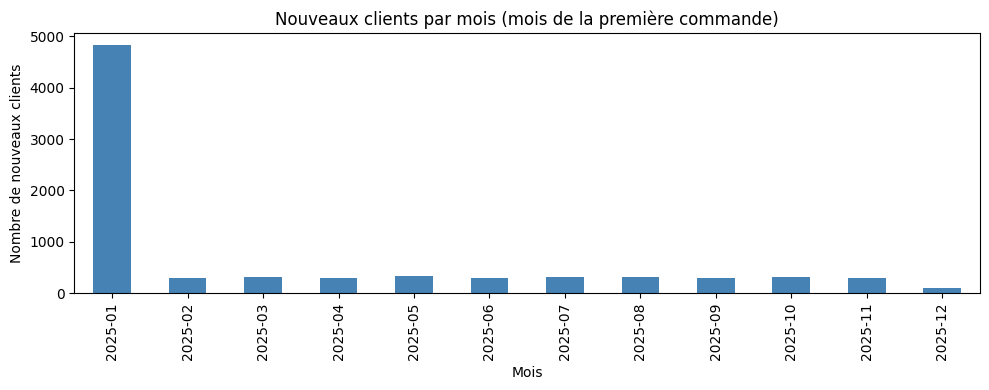

In [56]:
import matplotlib.pyplot as plt

nouveaux = (clients.groupBy(F.date_format("premiere_commande", "yyyy-MM").alias("mois"))
            .agg(F.count("*").alias("nouveaux_clients"))
            .orderBy("mois").toPandas())
print(nouveaux.to_string(index=False))

nouveaux.plot.bar(x="mois", y="nouveaux_clients", legend=False, figsize=(10, 4), color="steelblue")
plt.title("Nouveaux clients par mois (mois de la première commande)")
plt.xlabel("Mois")
plt.ylabel("Nombre de nouveaux clients")
plt.tight_layout()
plt.show()


janvier est vraiment elevé par ce que se sont les clients exiqtant des années précédentes

9.11) Pour chaque catégorie dominante : nombre de clients et chiffre d'affaires.

In [57]:
(clients.groupBy("categorie_dominante")
    .agg(F.count("*").alias("nb_clients"),
         F.round(F.sum("ca"), 0).alias("ca"),
         F.round(F.avg("ca"), 0).alias("ca_moyen_client"))
    .withColumn("part_ca_pct", F.round(F.col("ca") / ca_total * 100, 1))
    .orderBy(F.desc("ca"))
    .show(truncate=False))


+-------------------+----------+-----------+---------------+-----------+
|categorie_dominante|nb_clients|ca         |ca_moyen_client|part_ca_pct|
+-------------------+----------+-----------+---------------+-----------+
|Frais              |5393      |4.1299299E7|7658.0         |73.3       |
|Boissons           |709       |9527897.0  |13439.0        |16.9       |
|Épicerie           |1462      |3110142.0  |2127.0         |5.5        |
|Électronique       |15        |1705463.0  |113698.0       |3.0        |
|Livres             |399       |583397.0   |1462.0         |1.0        |
|Maison             |18        |72558.0    |4031.0         |0.1        |
|Collection         |1         |18193.0    |18193.0        |0.0        |
|Hygiène et beauté  |3         |4889.0     |1630.0         |0.0        |
+-------------------+----------+-----------+---------------+-----------+



9.12) Clients atypiques : les 10 clients dont `unites_par_ligne` est la plus élevée, avec le rapport à la moyenne de tous les clients, leur `ca` et leur `categorie_dominante`.

In [58]:
moy_upl = clients.agg(F.avg("unites_par_ligne")).first()[0]
print("Moyenne des unités par ligne (tous clients) :", round(moy_upl, 2))

(clients.withColumn("rapport_moyenne", F.round(F.col("unites_par_ligne") / moy_upl, 1))
    .select("client_id", "unites_par_ligne", "rapport_moyenne", "nb_commandes", "ca",
            "categorie_dominante", "segment")
    .orderBy(F.desc("unites_par_ligne"))
    .show(10, truncate=False))


Moyenne des unités par ligne (tous clients) : 2.89


+---------+----------------+---------------+------------+---------+-------------------+-------------------+
|client_id|unites_par_ligne|rapport_moyenne|nb_commandes|ca       |categorie_dominante|segment            |
+---------+----------------+---------------+------------+---------+-------------------+-------------------+
|CL00034  |219.24          |75.9           |20          |436778.7 |Électronique       |5) 50 000 € et plus|
|CL03089  |39.55           |13.7           |20          |357505.4 |Électronique       |5) 50 000 € et plus|
|CL03099  |33.97           |11.8           |22          |183802.7 |Électronique       |5) 50 000 € et plus|
|CL05722  |23.51           |8.1            |51          |109450.85|Épicerie           |5) 50 000 € et plus|
|CL07784  |20.52           |7.1            |55          |124598.05|Épicerie           |5) 50 000 € et plus|
|CL03672  |20.51           |7.1            |57          |112956.85|Épicerie           |5) 50 000 € et plus|
|CL02517  |19.04           |

le slcients atypiques sont peute etre des professionnels qui ont besoins d'acheter en gros

## 10) Data visualisation

Échelles de couleur : blanc ou clair pour 0, foncé pour les valeurs élevées.

10.1) Heatmap jour de la semaine × heure du nombre de commandes passées.

10.2) Carte du nombre de livraisons signées par commune ou arrondissement (`communes.geojson`, carte choroplèthe).

10.3) Heatmap heure × mois de la vitesse moyenne quand le livreur est à bord et que le véhicule roule.

10.4) Treemap du chiffre d'affaires : catégorie → sous-catégorie.

## 11) Sauvegarde et modélisation

11.2) **Modélisation.** Les analyses précédentes recalculent les mêmes jointures et agrégations. Proposez des collections MongoDB qui rendent ces questions immédiates : pour chaque collection, ce que représente un document, ses champs, ses tableaux imbriqués, et les questions des parties 5 à 9 qu'elle simplifie. Écrivez votre proposition dans la cellule ci-dessous.

*Votre proposition :*